<a href="https://colab.research.google.com/github/prakashrock0510-ni/project_4_App_users_behaviour/blob/main/Project_4_app_users.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

df= pd.read_csv("/content/app_user_behavior_dataset.csv")
df.shape

(50000, 25)

In [7]:
df["rating_given"] = df["rating_given"].fillna(df["rating_given"].median())

In [8]:
for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outliers = X[(X[col] < lower_limit)|(X[col] > upper_limit)][col].count()
    print(col, ":", outliers)

sessions_per_week : 181
avg_session_duration_min : 1572
daily_active_minutes : 181
feature_clicks_per_session : 745
notifications_opened_per_week : 660
in_app_search_count : 1054
pages_viewed_per_session : 0
crash_events_last_30_days : 398
support_tickets_raised : 8910
days_since_last_login : 0
ads_clicked_last_30_days : 70
content_downloads : 622
social_shares : 219


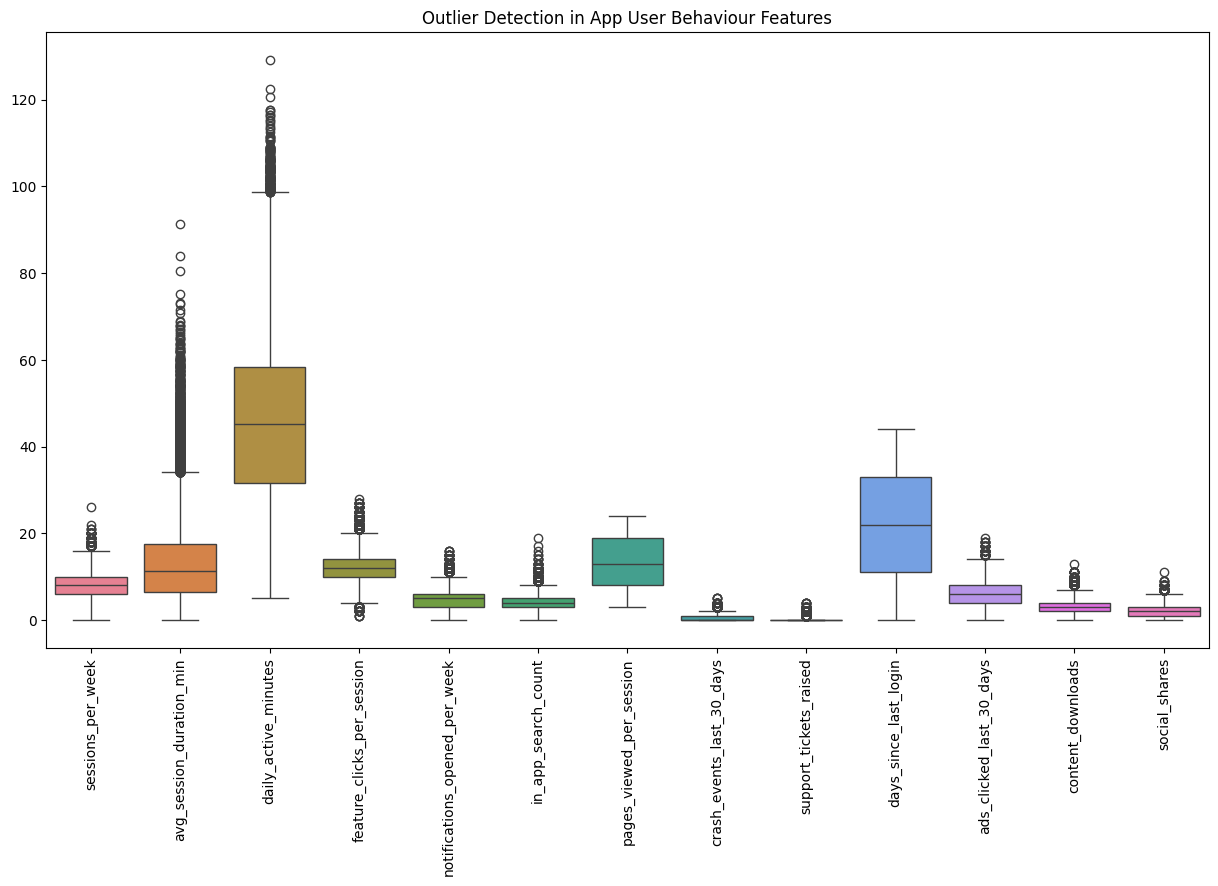

In [31]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=X)
plt.xticks(rotation=90)
plt.title("Outlier Detection in App User Behaviour Features")
plt.show()

In [10]:
outlier_results = []
for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outlier_count = ((X[col] < lower_limit) | (X[col] > upper_limit)).sum()
    outlier_percentage = (outlier_count / len(X)) * 100
    outlier_results.append({"Feature": col,"Outlier Count": outlier_count,"Outlier Percentage": round(outlier_percentage, 2)})
outlier_df = pd.DataFrame(outlier_results)
display(outlier_df)


,Feature,Outlier Count,Outlier Percentage
0,sessions_per_week,181,0.36
1,avg_session_duration_min,1572,3.14
2,daily_active_minutes,181,0.36
3,feature_clicks_per_session,745,1.49
4,notifications_opened_per_week,660,1.32
5,in_app_search_count,1054,2.11
6,pages_viewed_per_session,0,0.00
7,crash_events_last_30_days,398,0.80
8,support_tickets_raised,8910,17.82
9,days_since_last_login,0,0.00


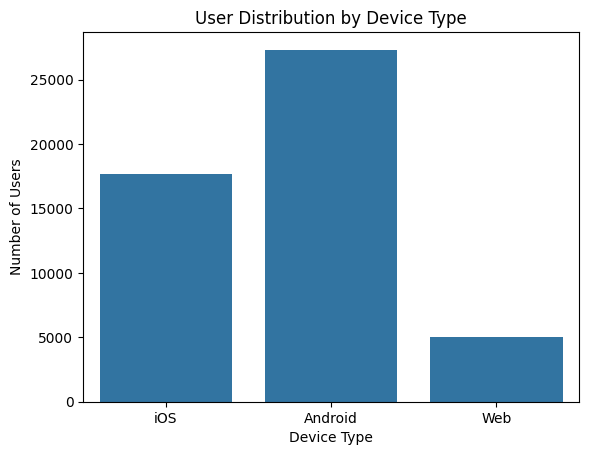

In [11]:
sns.countplot(data=df, x="device_type")
plt.title("User Distribution by Device Type")
plt.xlabel("Device Type")
plt.ylabel("Number of Users")
plt.show()

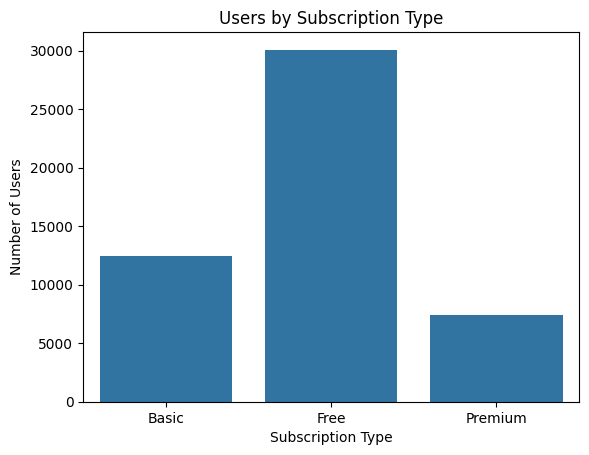

In [12]:
sns.countplot(data=df, x="subscription_type")
plt.title("Users by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Number of Users")
plt.show()

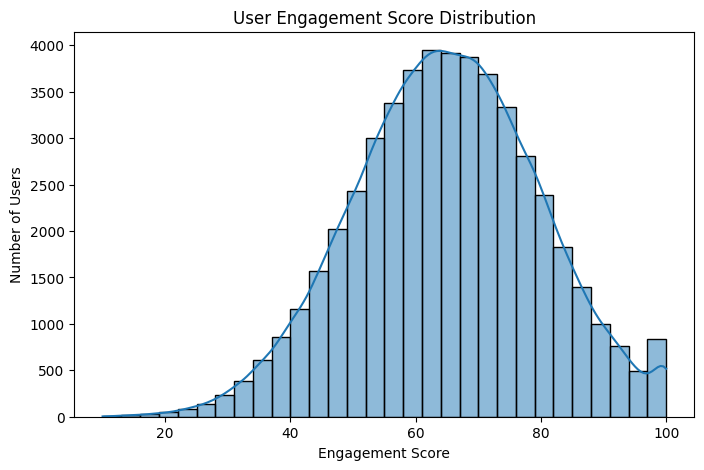

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df["engagement_score"], bins=30, kde=True)
plt.title("User Engagement Score Distribution")
plt.xlabel("Engagement Score")
plt.ylabel("Number of Users")
plt.show()

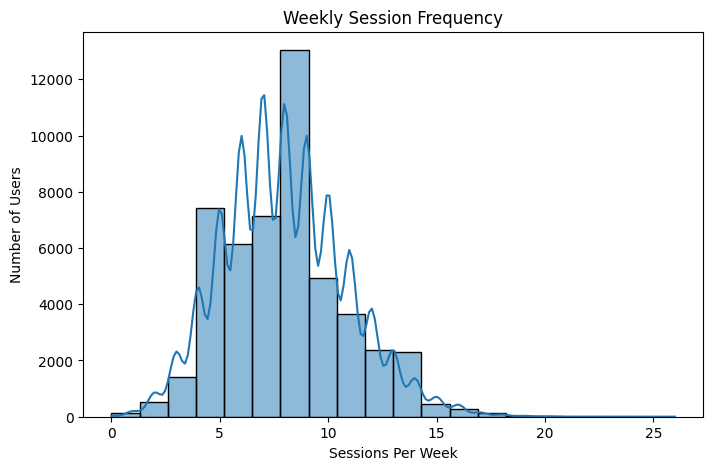

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df["sessions_per_week"], bins=20, kde=True)
plt.title("Weekly Session Frequency")
plt.xlabel("Sessions Per Week")
plt.ylabel("Number of Users")
plt.show()

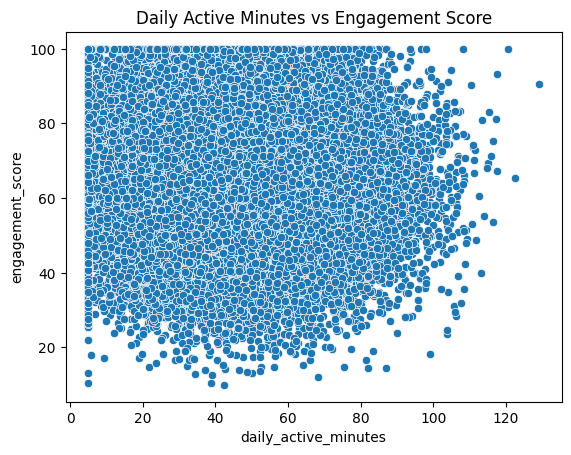

In [15]:
sns.scatterplot(data=df,x="daily_active_minutes",y="engagement_score")
plt.title("Daily Active Minutes vs Engagement Score")
plt.show()

In [16]:
features = [
    "sessions_per_week",
    "avg_session_duration_min",
    "daily_active_minutes",
    "feature_clicks_per_session",
    "notifications_opened_per_week",
    "in_app_search_count",
    "pages_viewed_per_session",
    "crash_events_last_30_days",
    "support_tickets_raised",
    "days_since_last_login",
    "ads_clicked_last_30_days",
    "content_downloads",
    "social_shares"
]

X = df[features]


In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Scaled Data Shape:", X_scaled.shape)

Scaled Data Shape: (50000, 13)


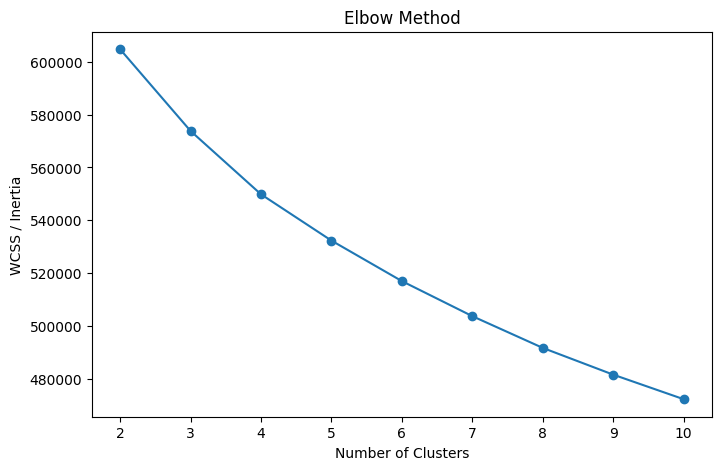

In [18]:
wcss = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i,random_state=42,n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
plt.figure(figsize=(8,5))
plt.plot(range(2,11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS / Inertia")
plt.show()

In [32]:
for i in range(2, 7):
    kmeans = KMeans(n_clusters=i,random_state=42,n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled,labels,sample_size=5000,random_state=42)
    print("Clusters:", i)
    print("Silhouette Score:", score)


Clusters: 2
Silhouette Score: 0.11922358761106523
Clusters: 3
Silhouette Score: 0.06555036755305055
Clusters: 4
Silhouette Score: 0.060879529878254186
Clusters: 5
Silhouette Score: 0.060180382400241504
Clusters: 6
Silhouette Score: 0.05659295968478896


In [21]:
kmeans = KMeans(n_clusters=2,random_state=42,n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)
print(df["cluster"].value_counts().sort_index())
df[["user_id", "cluster"]].head(10)
df["cluster"].value_counts().sort_index()
cluster_profile = df.groupby("cluster")[features + ["engagement_score", "churn_risk_score"]].mean()
print(cluster_profile.round(2))


cluster
0     8910
1    41090
Name: count, dtype: int64
         sessions_per_week  avg_session_duration_min  daily_active_minutes  \
cluster                                                                      
0                     8.01                     13.20                 45.04   
1                     8.00                     13.14                 45.19   

         feature_clicks_per_session  notifications_opened_per_week  \
cluster                                                              
0                             11.96                           5.01   
1                             12.03                           4.99   

         in_app_search_count  pages_viewed_per_session  \
cluster                                                  
0                        4.0                     13.47   
1                        4.0                     13.47   

         crash_events_last_30_days  support_tickets_raised  \
cluster                                                

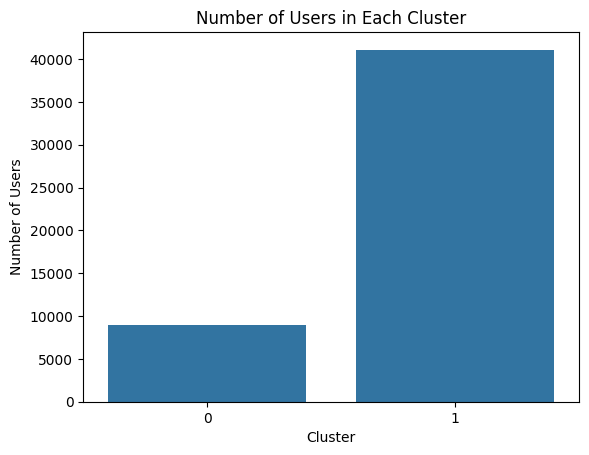

In [23]:
sns.countplot(data=df, x="cluster")
plt.title("Number of Users in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Users")
plt.show()

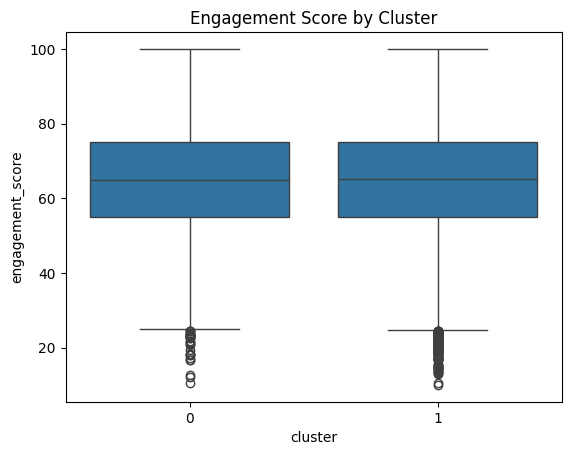

In [24]:
sns.boxplot(data=df,x="cluster",y="engagement_score")
plt.title("Engagement Score by Cluster")
plt.show()

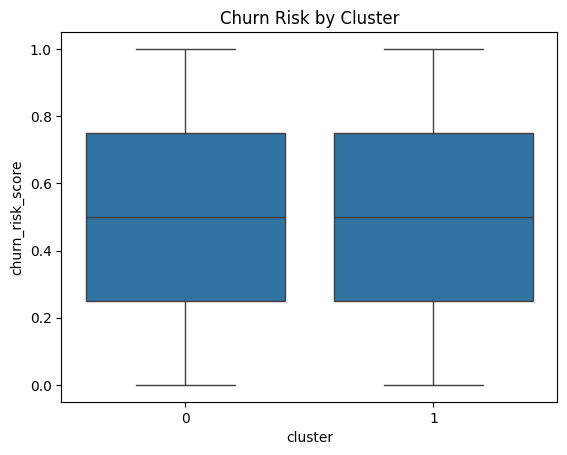

In [25]:
sns.boxplot(data=df,x="cluster",y="churn_risk_score")
plt.title("Churn Risk by Cluster")
plt.show()


In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca,columns=["PCA1", "PCA2"])
pca_df["cluster"] = df["cluster"]

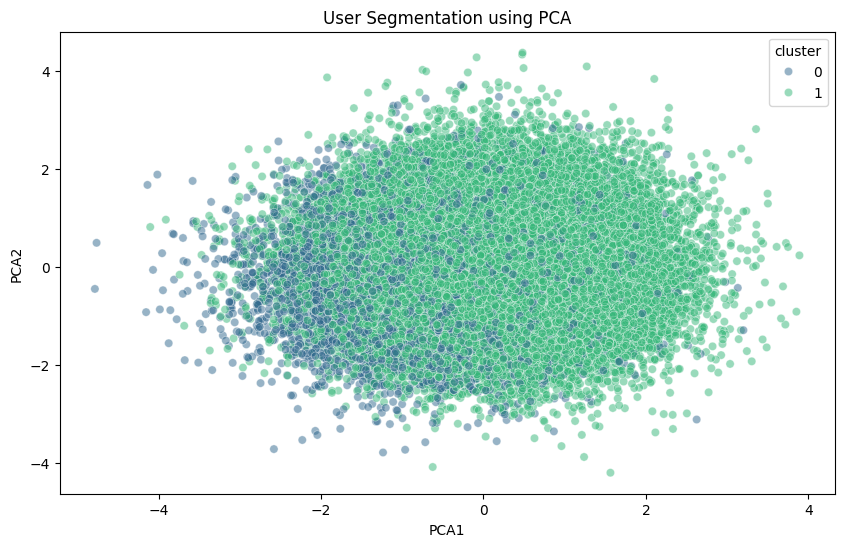

In [27]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=pca_df,x="PCA1",y="PCA2",hue="cluster",palette="viridis",alpha=0.5)
plt.title("User Segmentation using PCA")
plt.show()

In [28]:
sil_score = silhouette_score(X_scaled, df["cluster"],sample_size=5000,random_state=42)
db_score = davies_bouldin_score(X_scaled,df["cluster"])
print("Silhouette Score:", sil_score)
print("Davies Bouldin Score:", db_score)


Silhouette Score: 0.11922358761106523
Davies Bouldin Score: 2.760604977606512


In [29]:
cluster_0_users = df[df["cluster"] == 0]
print(cluster_0_users[["user_id", "engagement_score", "churn_risk_score"]])
cluster_1_users = df[df["cluster"] == 1]
print(cluster_1_users[["user_id", "engagement_score", "churn_risk_score"]])

       user_id  engagement_score  churn_risk_score
8       100008             72.85              0.08
13      100013             67.25              0.48
28      100028             44.53              0.03
41      100041             50.22              0.44
48      100048             59.40              0.88
...        ...               ...               ...
49974   149974             58.40              0.19
49977   149977             88.92              0.25
49994   149994             61.23              0.89
49995   149995             68.97              0.39
49996   149996             64.84              0.12

[8910 rows x 3 columns]
       user_id  engagement_score  churn_risk_score
0       100000             55.79              0.31
1       100001             82.39              0.87
2       100002             42.49              0.63
3       100003             62.81              0.43
4       100004             38.21              0.43
...        ...               ...               ...
49992 

In [34]:
cluster_ranking = (df.groupby("cluster")["engagement_score"].mean().sort_values(ascending=False))
print(cluster_ranking)

cluster
1    64.946663
0    64.911563
Name: engagement_score, dtype: float64


In [35]:
cluster_names = {}
for rank, cluster in enumerate(cluster_ranking.index):
    if rank == 0:
        cluster_names[cluster] = "High Engagement Users"
    elif rank == len(cluster_ranking) - 1:
        cluster_names[cluster] = "Low Engagement Users"
    elif rank == 1:
        cluster_names[cluster] = "Moderate Engagement Users"
    else:
        cluster_names[cluster] = "Occasional Users"
df["user_segment"] = df["cluster"].map(cluster_names)
print(df["user_segment"].value_counts())

user_segment
High Engagement Users    41090
Low Engagement Users      8910
Name: count, dtype: int64


In [36]:
business_actions = {"High Engagement Users":"Provide loyalty rewards and premium offers",
    "Moderate Engagement Users":"Encourage more app usage through personalized recommendations",
    "Low Engagement Users":"Launch retention campaigns and re-engagement offers",
    "Occasional Users":"Send reminders and promotional notifications"}
df["recommended_action"] = df["user_segment"].map(business_actions)

In [37]:
customer_action_list = df[["user_id","cluster","user_segment","engagement_score","churn_risk_score","recommended_action"]]
display(customer_action_list.head(20))

,user_id,cluster,user_segment,engagement_score,churn_risk_score,recommended_action
0,100000,1,High Engagement Users,55.79,0.31,Provide loyalty rewards and premium offers
1,100001,1,High Engagement Users,82.39,0.87,Provide loyalty rewards and premium offers
2,100002,1,High Engagement Users,42.49,0.63,Provide loyalty rewards and premium offers
3,100003,1,High Engagement Users,62.81,0.43,Provide loyalty rewards and premium offers
4,100004,1,High Engagement Users,38.21,0.43,Provide loyalty rewards and premium offers
5,100005,1,High Engagement Users,91.45,0.65,Provide loyalty rewards and premium offers
6,100006,1,High Engagement Users,63.30,0.78,Provide loyalty rewards and premium offers
7,100007,1,High Engagement Users,84.81,0.51,Provide loyalty rewards and premium offers
8,100008,0,Low Engagement Users,72.85,0.08,Launch retention campaigns and re-engagement o...
9,100009,1,High Engagement Users,55.92,0.19,Provide loyalty rewards and premium offers


In [38]:
business_summary = df.groupby("user_segment").agg(total_users=("user_id", "count"),avg_engagement=("engagement_score", "mean"),
    avg_churn_risk=("churn_risk_score", "mean")).round(2)
display(business_summary)

,total_users,avg_engagement,avg_churn_risk
user_segment,,,
High Engagement Users,41090,64.95,0.5
Low Engagement Users,8910,64.91,0.5
